# 1. System Environment Configuration
Configure system paths to import custom packages from the parent directory.

In [97]:
import sys
import os
from pathlib import Path

# Add parent directory to system path to enable importing custom modules
sys.path.append(str(Path(os.getcwd()).parent))

# 2. Import Dependencies
Import necessary libraries including custom utility packages, Qiskit for quantum circuit simulation, and numerical tools.

In [98]:
# Custom packages for Unitary, POVM, States, and Linear Algebra tools
from packages.unitary import *
from packages.povms import *
from packages.utils import *
from packages.states import *
from packages.linalg import *
from packages.decomposition import kak_decomposition

# Qiskit Core & Quantum Info
from qiskit import QuantumCircuit
from qiskit.quantum_info import (
    DensityMatrix, 
)
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# Qiskit Aer & Noise Models
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    QuantumError,
    ReadoutError,
    depolarizing_error,
    pauli_error,
    thermal_relaxation_error,
)

# Numerical & Optimization tools
import numpy as np
from scipy.optimize import brute, brentq

# 3. Load SIC-POVM Fiducial Vector
Load the pre-computed fiducial vector that generates the Symmetric Informationally Complete (SIC) POVM.
This vector is used to construct the measurement unitary.

In [99]:
# Load SIC-POVM fiducial vector from data file
# Reference: PhysRevA.86.062107
# One can also load other fiducial vector
sic_fiducial_vector = np.load(r'../data/sic_phi_vectors/PRA_86_062107.npy')

# 4. Configure Noise Model
Set up the noise model for the simulation. In this baseline experiment, we use an ideal noiseless model.

In [100]:
# Use None for ideal noiseless simulation
noise_model = None

# 5. Experiment Parameters
Define key parameters for the shadow estimation experiment, including shot count, system size, and optimization settings.

In [101]:
num_shots = 50_000_000        # Number of measurement shots
num_qubits = 2              # Number of qubits in the system
use_cloud_backend = False    # Whether to use cloud backend (False for local simulator)
save_intermediate_data = True # Whether to save/return data for each shot
optimization_mode = 2        # Circuit optimization level: 2 = Optimized for SIC-POVM

# 6. State Preparation
Initialize the target quantum state for fidelity estimation. Currently set to the |0> state.

In [102]:
# Available states
random_state = get_random_state(num_qubits)
zero_state = get_zero_state(num_qubits)
one_state = get_one_state(num_qubits)
ghz_state = get_ghz_state(num_qubits) # Example for entangled state

# Select target state
target_state_vector = ghz_state

# 7. Define Observable for Fidelity Estimation
For pure state fidelity estimation $F = \langle \psi | \rho | \psi \rangle$, the observable is the projector of the target state $O = | \psi \rangle \langle \psi |$.

In [103]:
# Create density matrix from the target state vector to use as the observable
observable_matrix = DensityMatrix.from_instruction(target_state_vector).data

# 8. Circuit Construction Functions
Helper functions to construct the POVM measurement circuit.
- `attach_ancilla_and_measure`: Expands the system with ancilla qubits for Naimark's dilation.
- `construct_sic_measurement_circuit`: Generates the compiled circuit for SIC-POVM, applying optimizations based on the selected method.

In [104]:
def attach_ancilla_and_measure(qc, measured_qubits, two_qubit_subcircuit):
    """
    Expands the original circuit with ancilla qubits to implement POVM via Naimark dilation.
    """
    num_system_qubits = qc.num_qubits
    num_measurements = len(measured_qubits)
    
    # Create a larger circuit with system + ancilla qubits
    # Classical register size = num_measurements * 2 (one for system, one for ancilla result)
    expanded_circuit = QuantumCircuit(num_system_qubits + num_measurements, num_measurements * 2)
    expanded_circuit.compose(qc, qubits=range(num_system_qubits), inplace=True)
    
    for i, target_qubit in enumerate(measured_qubits):
        ancilla_index = num_system_qubits + i 
        # Append the POVM implementation unitary (U_P)
        expanded_circuit.compose(two_qubit_subcircuit, qubits=[target_qubit, ancilla_index], inplace=True)
    
    expanded_circuit.barrier()
    
    # Perform projective measurements on both system and ancilla qubits
    for i, target_qubit in enumerate(measured_qubits):
        expanded_circuit.measure(target_qubit, i) # Measure system qubit
    for i, target_qubit in enumerate(measured_qubits):
        ancilla_index = num_system_qubits + i 
        expanded_circuit.measure(ancilla_index, num_measurements + i) # Measure ancilla qubit
        
    return expanded_circuit

def construct_sic_measurement_circuit(target_state_qc, sic_fiducial, optimization_mode=0, measured_qubits=None):
    """
    Constructs the full measurement circuit for SIC-POVM shadow estimation.
    
    Args:
        target_state_qc: QuantumCircuit preparing the state.
        sic_fiducial: Fiducial vector defining the SIC-POVM.
        optimization_mode: 0=Standard, 1=KAK-based, 2=Analytical Optimization (S4).
        measured_qubits: List of qubits to measure (default: all).
        
    Returns:
        tuple: (Compiled QuantumCircuit, boolean requires_cnot_relabeling)
    """
    # 1. Generate the unitary matrix U_P from the SIC fiducial vector
    unitary_matrix = sic_phi_2_unitary(sic_fiducial)
    
    requires_cnot_relabeling = False
    
    # Method 0: Standard decomposition (Qiskit default)
    if optimization_mode == 0:
        povm_unitary_circuit = unitary2circuit(unitary_matrix)
        
    # Method 1: Optimization via KAK decomposition (numerical search for minimal CNOTs)
    elif optimization_mode == 1:
        def interaction_strength(gamma2):
            # Construct a controlled-U3 gate to adjust parameters
            # Aim to minimize the 'z' interaction coefficient in KAK decomposition
            control_op = controlled_U3_pauli(0, gamma2, 0)
            _, _, z = kak_decomposition(unitary_matrix @ control_op)
            return np.abs(z) 
            
        def interaction_strength_signed(gamma2):
             control_op = controlled_U3_pauli(0, gamma2, 0)
             _, _, z = kak_decomposition(unitary_matrix @ control_op)
             return z
             
        search_range = (0, 1 * np.pi)
        # Coarse search
        gamma2_opt_approx = brute(interaction_strength, [search_range], Ns=1000, full_output=False, finish=None)
        # Fine tuning
        gamma2_opt = brentq(interaction_strength_signed, gamma2_opt_approx - np.pi/100, gamma2_opt_approx + np.pi/100, xtol=1e-30)
        
        control_op_opt = controlled_U3_pauli(0, gamma2_opt, 0)
        optimized_unitary = unitary_matrix @ control_op_opt
        povm_unitary_circuit = unitary2circuit(optimized_unitary)
        
    # Method 2: Analytical Optimization (S4: Shallower Single Setting Shadow)
    elif optimization_mode == 2:
        # Use analytical method to find optimal parameters (U_S, phases, etc.)
        # get_sic_parameters corresponds to the refactored function from previous discussions
        u_s, phases, requires_cnot_relabeling = get_sic_parameters(unitary_matrix) 
        
        # Construct the optimized circuit structure (1 CNOT)
        povm_unitary_circuit = QuantumCircuit(2)
        # Apply single-qubit rotation U_S
        from qiskit.circuit.library import UnitaryGate
        povm_unitary_circuit.append(UnitaryGate(u_s), [0])
        
        # Apply standard Bell-measurement-like structure
        povm_unitary_circuit.rx(np.arccos(1/np.sqrt(3)), 1)
        povm_unitary_circuit.rz(3 * np.pi / 4, 1)
        povm_unitary_circuit.cx(1, 0)
        povm_unitary_circuit.h(1)       
    
    if measured_qubits is None:
        measured_qubits = range(target_state_qc.num_qubits)
        
    final_circuit = attach_ancilla_and_measure(target_state_qc, measured_qubits, povm_unitary_circuit)
    
    return final_circuit, requires_cnot_relabeling

# 9. Circuit Compilation and Execution
Compile the circuit for the simulator and execute to collect measurement shots.

Execution complete. Collected 50000000 shots.


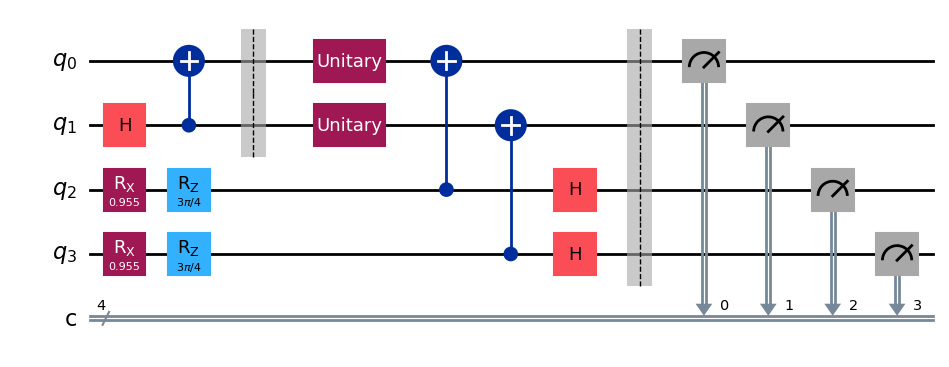

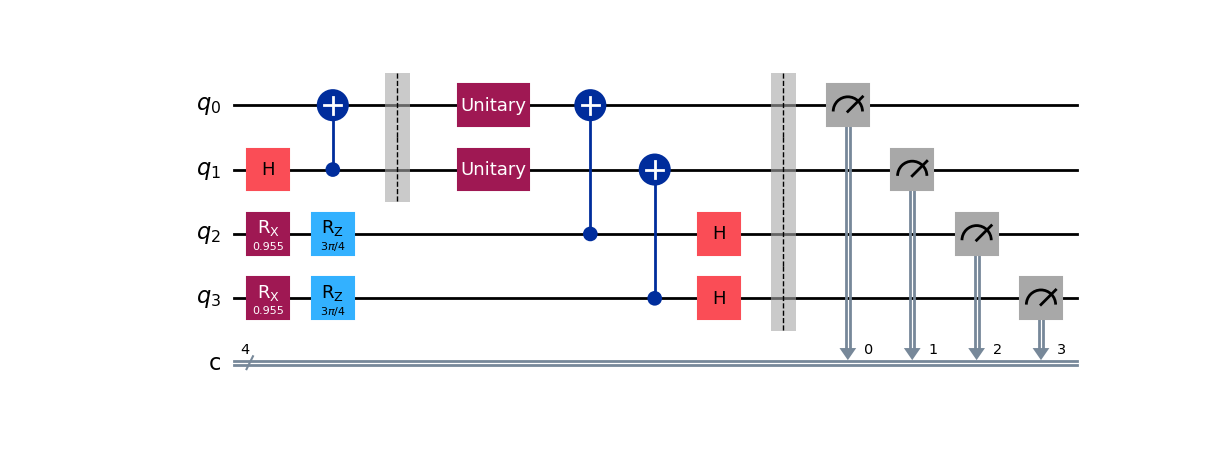

In [105]:
# 1. Construct the measurement circuit
target_state_qc = target_state_vector
measurement_circuit, requires_relabeling = construct_sic_measurement_circuit(
    target_state_qc, 
    sic_fiducial_vector, 
    optimization_mode
)

# 2. Configure Simulator
backend_sim = AerSimulator(noise_model=noise_model)

# 3. Transpile/Compile
# Using optimization_level=0 to preserve our custom circuit structure
pass_manager = generate_preset_pass_manager(optimization_level=0, backend=backend_sim)
compiled_circuit = pass_manager.run(measurement_circuit)

# 4. Execute
# memory=True is required to get single-shot results for shadow estimation
job = backend_sim.run(compiled_circuit, shots=num_shots, memory=True)
result_memory = job.result().get_memory()

print(f"Execution complete. Collected {len(result_memory)} shots.")
# Optional: Visualize circuit
compiled_circuit.draw('mpl')

# 10. Classical Shadow Post-processing
Process the measurement results to estimate the expectation value of the observable.
Function `estimate_shadow_expectation` reconstructs the shadow snapshots and computes the average.

In [106]:
def estimate_shadow_expectation(measurement_results, sic_fiducial, apply_relabeling, return_trajectory, observable_func, *func_args):
    """
    Reconstructs classical shadows from measurement results and estimates expectation values.
    
    Args:
        measurement_results: List of bitstrings from experiment.
        sic_fiducial: Fiducial vector for SIC-POVM.
        apply_relabeling: Boolean, whether to swap '10' and '11' keys (from optimization).
        return_trajectory: If True, returns the convergence trajectory. If False, returns final average.
        observable_func: Function to calculate property from density matrix (e.g., expectation value).
        func_args: Arguments for observable_func.
    """
    # Pre-compute Frame Operator inverse and POVM elements mapping
    # Note: compute_frame_operator_inv_and_dict is the refactored name for compute_sp_inv_and_dict
    Sp_inv, povm_elements_map = compute_frame_operator_inv_and_dict(sic_fiducial, apply_relabeling)
    
    # Pre-compute the reconstruction matrix M^-1 |E_i>> for each outcome to speed up processing
    # reconstruction_cache[bitstring] = rho_hat (snapshot)
    reconstruction_cache = {
        bitstring: devectorize_matrix(Sp_inv @ vec_povm) 
        for bitstring, vec_povm in povm_elements_map.items()
    }
    
    processed_values_cache = {}
    
    def get_value_for_outcome(outcome_bitstring):
        """Helper to compute f(rho_hat) for a specific bitstring, with caching."""
        if outcome_bitstring not in processed_values_cache:
            # Handle multi-qubit results by splitting and taking tensor products
            # snapshot_data_split handles parsing the combined bitstring
            split_outcomes = snapshot_data_split(outcome_bitstring)
            
            # Reconstruct local snapshots
            local_snapshots = [reconstruction_cache[sub] for sub in split_outcomes]
            
            # Global snapshot is tensor product of local snapshots
            global_snapshot = compute_kronecker_product(local_snapshots)
            
            # Calculate the property (e.g., Tr(O * rho_hat))
            processed_values_cache[outcome_bitstring] = observable_func(global_snapshot, *func_args)
            
        return processed_values_cache[outcome_bitstring]
    
    # Calculate estimates
    if not return_trajectory:
        # Just return the final average
        total_sum = sum(get_value_for_outcome(res) for res in measurement_results)
        return total_sum / len(measurement_results)
    else:
        # Return the sequence of single-shot estimates for convergence plotting
        trajectory = [get_value_for_outcome(res) for res in measurement_results]
        return trajectory

# 11. Compute Fidelity Estimates
Run the shadow estimation to get the fidelity convergence trajectory.

In [107]:
# 11. Compute Fidelity Estimates

# Define fidelity function
def expectation_value(rho, observable):
    # Tr(Obs * rho). For pure states, this is Fidelity.
    return np.trace(observable @ rho)

# Run shadow estimation
fidelity_trajectory = estimate_shadow_expectation(
    result_memory,          
    sic_fiducial_vector,     
    requires_relabeling,    
    save_intermediate_data,  
    expectation_value,     
    observable_matrix     
)

# Print results
print(f"Last Single-Shot Estimate: {fidelity_trajectory[-1]}")
print(f"Average Fidelity: {np.mean(fidelity_trajectory).real:.6f}")

Last Single-Shot Estimate: (2.499999999999999+0j)
Average Fidelity: 1.000111


# 12. Visualization: Convergence Analysis
Plot the convergence of the estimated fidelity as the number of shots increases.

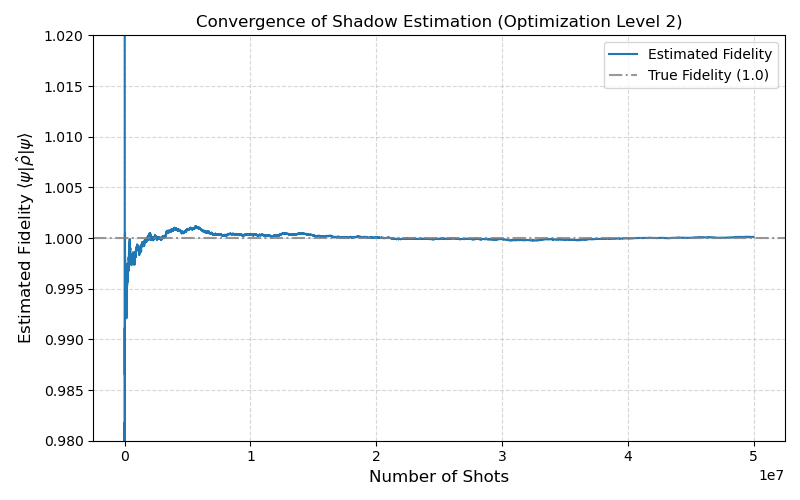

In [108]:
%matplotlib widget
from matplotlib import pyplot as plt

# Configuration
line_style = {'color': 'grey', 'linestyle': 'dashdot', 'alpha': 0.8, 'linewidth': 1.5}
sample_step = 1000  # Downsample for plotting performance
xlabel = 'Number of Shots'
ylabel = r'Estimated Fidelity $\langle \psi | \hat{\rho} | \psi \rangle$'
fontsize = 12

# Calculate cumulative moving average
# Use real part because fidelity is physically real (discard imaginary noise)
fidelity_values = np.array(fidelity_trajectory).real
cumulative_average = np.cumsum(fidelity_values) / np.arange(1, len(fidelity_values) + 1)

# Downsampling for plot
plot_indices = list(range(0, len(cumulative_average), sample_step))
if len(cumulative_average) - 1 not in plot_indices:
    plot_indices.append(len(cumulative_average) - 1)
    
plot_data = cumulative_average[plot_indices]

# Plotting
plt.figure(figsize=(8, 5))
plt.plot(plot_indices, plot_data, label='Estimated Fidelity', color='#1f77b4')
plt.ylim(0.98,1.02)
# Plot theoretical true value
true_fidelity = np.trace(observable_matrix @ observable_matrix).real # Should be 1.0
plt.axhline(y=true_fidelity, label='True Fidelity (1.0)', **line_style)

# Styling
plt.xlabel(xlabel, fontsize=fontsize)
plt.ylabel(ylabel, fontsize=fontsize)
plt.title(f'Convergence of Shadow Estimation (Optimization Level {optimization_mode})', fontsize=fontsize)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()